# Assignment 2: Transfer Learning Across Two Datasets

**Name:** *Jack Nelson*

**Prerequisite:** Transfer Learning lecture (frozen feature extraction)

This assignment uses frozen transfer learning, exactly what was covered in lecture: load a pretrained base, freeze it, add a new head, train only that. You'll do this twice, on two different datasets, and compare the results.

Data loading is provided for you below. Everything after that, building the model, training, evaluating, and reflecting, is yours to write, following the general instructions in each section.

**Submission:** GitHub repo URL and this notebook's URL on Canvas.

## Setup — Imports

In [37]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

---
# Part 1: Fire/Smoke Detection

## 1A — Load the Data

In [38]:
!pip install legacy-cgi --quiet
!pip install opendatasets --quiet

import opendatasets as od
od.download("https://www.kaggle.com/datasets/phylake1337/fire-dataset")

for root, dirs, files in os.walk("fire-dataset"):
    print(root, "->", dirs[:5], f"({len(files)} files)")

Skipping, found downloaded files in "./fire-dataset" (use force=True to force download)
fire-dataset -> ['fire_dataset'] (0 files)
fire-dataset/fire_dataset -> ['non_fire_images', 'fire_images'] (0 files)
fire-dataset/fire_dataset/non_fire_images -> [] (244 files)
fire-dataset/fire_dataset/fire_images -> [] (755 files)


In [39]:
data_dir_fire = "fire-dataset/fire_dataset"

img_size = (224, 224)
batch_size = 32

train_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_fire = tf.keras.utils.image_dataset_from_directory(
    data_dir_fire, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_fire = tf.data.experimental.cardinality(val_test_raw_fire)
test_raw_fire = val_test_raw_fire.take(val_test_batches_fire // 2)
val_raw_fire = val_test_raw_fire.skip(val_test_batches_fire // 2)

class_names_fire = train_raw_fire.class_names
print("Class names:", class_names_fire)

Found 999 files belonging to 2 classes.
Using 700 files for training.
Found 999 files belonging to 2 classes.
Using 299 files for validation.
Class names: ['fire_images', 'non_fire_images']


## 1B — Inspect the Data

Before doing anything else, take a real look at what you loaded. How many images does each class have? Is there anything about the data itself that might affect how you should split it, or how you should interpret your model's results later?

Write whatever code you need to answer this for yourself.

Class 'non_fire_images': 244 images
Class 'fire_images': 755 images


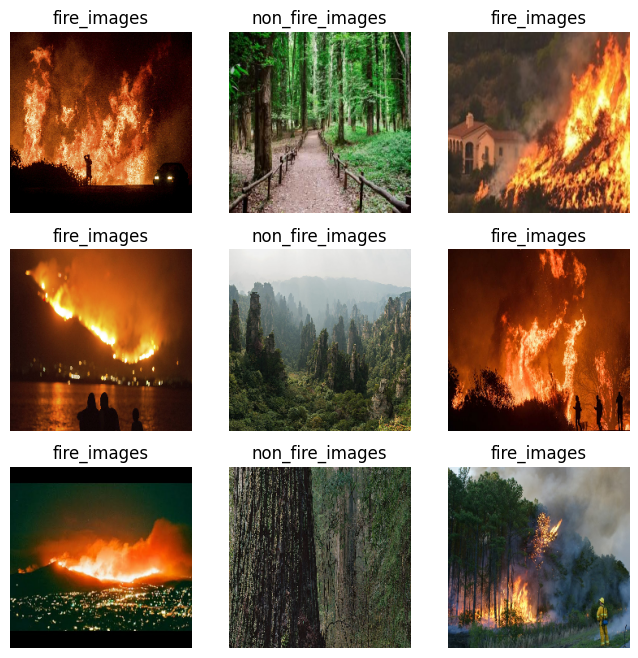

In [40]:
for class_name in os.listdir(data_dir_fire):
    class_path = os.path.join(data_dir_fire, class_name)
    if os.path.isdir(class_path):
        print(f"Class '{class_name}': {len(os.listdir(class_path))} images")

plt.figure(figsize=(8, 8))
for images, labels in train_raw_fire.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names_fire[labels[i]])
        plt.axis("off")
plt.show()



There are 755 fire images and 244 not fire images. The dataset is imbalanced, so a model could score high accuracy just by leaning toward "fire." Accuracy alone isn't enough here, so a confusion matrix will be important to see how many images of each class are classified incorrectly.

*What did you notice about this dataset? Does it change how you'll approach the next steps?*



## 1C — Build a Frozen Transfer Learning Model

Using MobileNetV2 as your pretrained base:
- Freeze the base model entirely
- Add a new output layer appropriate for this task (think about how many classes you're predicting, and what that means for your output layer's size, activation, and loss function)
- Remember the pattern from lecture for how the base model should be called

Preprocess your data (`train_raw_fire`, `val_raw_fire`, `test_raw_fire`) using MobileNetV2's expected preprocessing before building your model.

In [41]:
# Preprocess the data here
def preprocess_mobilenet(image, label):
    return preprocess_input(image), label

train_ds_fire = train_raw_fire.map(preprocess_mobilenet)
val_ds_fire = val_raw_fire.map(preprocess_mobilenet)
test_ds_fire = test_raw_fire.map(preprocess_mobilenet)


In [42]:
# Build your model here
base_model_fire = MobileNetV2(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
base_model_fire.trainable = False  # freeze the base

x = base_model_fire.output
x = GlobalAveragePooling2D()(x)
output = Dense(1, activation="sigmoid")(x)  # binary: 1 unit + sigmoid
fire_model = Model(inputs=base_model_fire.input, outputs=output)


In [43]:
# Compile your model here
fire_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
fire_model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 1D — Train and Evaluate

In [44]:
# Train your model here
fire_history = fire_model.fit(train_ds_fire, validation_data=val_ds_fire, epochs=5)


Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 36s 803ms/step - accuracy: 0.8543 - loss: 0.3219 - val_accuracy: 0.9209 - val_loss: 0.2125
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 572ms/step - accuracy: 0.9757 - loss: 0.1287 - val_accuracy: 0.9640 - val_loss: 0.1205
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 532ms/step - accuracy: 0.9800 - loss: 0.0895 - val_accuracy: 0.9568 - val_loss: 0.1005
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 529ms/step - accuracy: 0.9857 - loss: 0.0724 - val_accuracy: 0.9712 - val_loss: 0.0791
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 541ms/step - accuracy: 0.9900 - loss: 0.0628 - val_accuracy: 0.9856 - val_loss: 0.0640


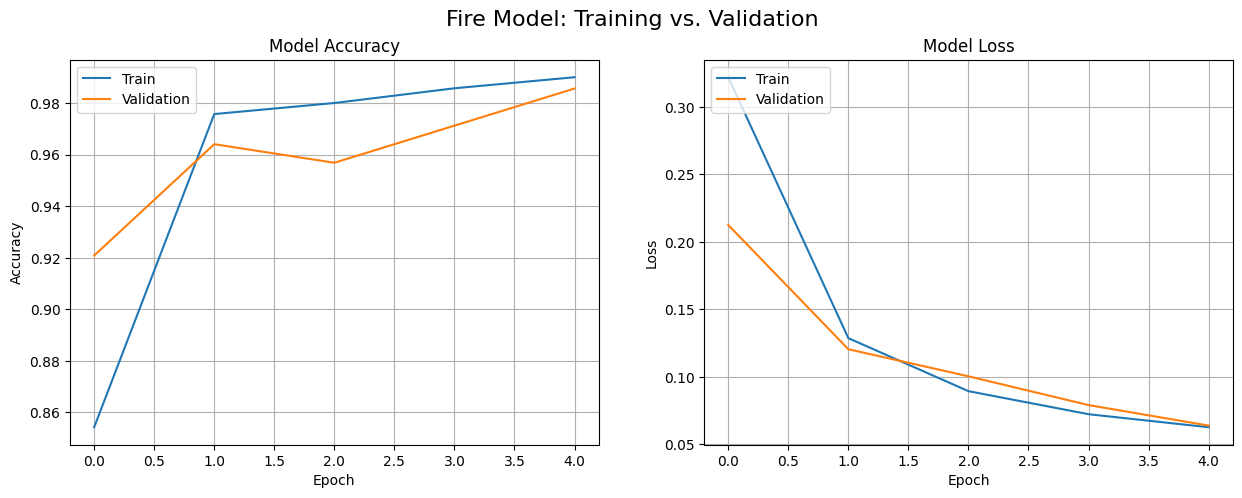

Validation Accuracy: 0.9640
Test Accuracy:       0.9812


In [45]:
# Report validation and test accuracy here
def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    ax1.plot(history.history["accuracy"]); ax1.plot(history.history["val_accuracy"])
    ax1.set_title("Model Accuracy"); ax1.set_ylabel("Accuracy"); ax1.set_xlabel("Epoch")
    ax1.legend(["Train", "Validation"], loc="upper left"); ax1.grid(True)
    ax2.plot(history.history["loss"]); ax2.plot(history.history["val_loss"])
    ax2.set_title("Model Loss"); ax2.set_ylabel("Loss"); ax2.set_xlabel("Epoch")
    ax2.legend(["Train", "Validation"], loc="upper left"); ax2.grid(True)
    fig.suptitle(title, fontsize=16)
    plt.show()

plot_history(fire_history, "Fire Model: Training vs. Validation")

fire_val_loss, fire_val_acc = fire_model.evaluate(val_ds_fire, verbose=0)
fire_test_loss, fire_test_acc = fire_model.evaluate(test_ds_fire, verbose=0)
print(f"Validation Accuracy: {fire_val_acc:.4f}")
print(f"Test Accuracy:       {fire_test_acc:.4f}")


## 1E — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** In this context, is a false negative (missing a real fire) or a false positive (a false alarm) more costly? How might that change the decision threshold you'd actually use in practice, rather than the default 0.5?

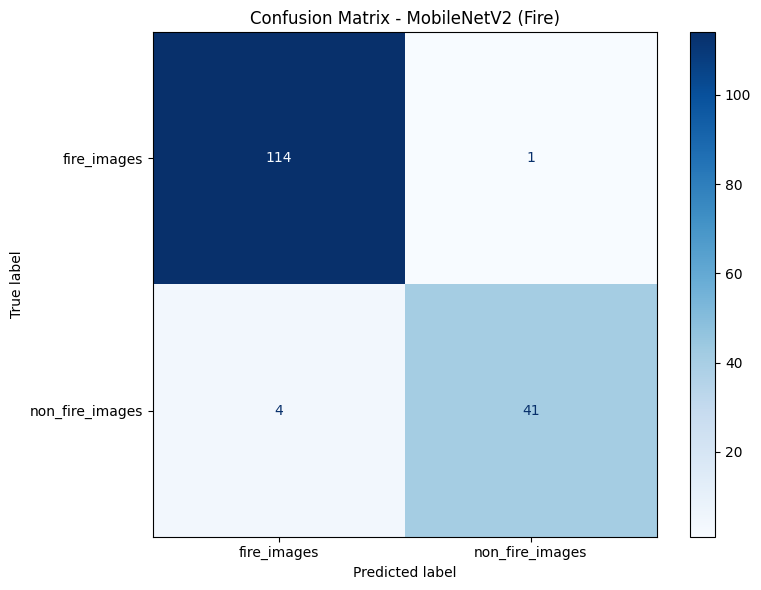

In [46]:
# Build your confusion matrix here
def predict_with_labels(model, ds):
    # Gather labels and predictions in the same pass so they stay aligned (datasets are shuffled)
    y_true, y_prob = [], []
    for images, labels in ds:
        y_true.append(labels.numpy())
        y_prob.append(model.predict(images, verbose=0))
    return np.concatenate(y_true), np.concatenate(y_prob)

y_true_fire, fire_probs = predict_with_labels(fire_model, test_ds_fire)
y_pred_fire = (fire_probs.flatten() >= 0.5).astype(int)

cm_fire = confusion_matrix(y_true_fire, y_pred_fire)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm_fire, display_labels=class_names_fire).plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Confusion Matrix - MobileNetV2 (Fire)")
plt.tight_layout()
plt.show()


*Your answer:*

A false negative is much more costly than a false alarm. A missed fire could mean lives and property lost, while a false alarm only costs someone a few minutes to check. A model that produces many false negatives wouldn't be reliable as a fire detector.

In practice the decision threshold should be moved away from 0.5 so the model errs toward flagging fire.



---
# Part 2: Satellite Land-Use Classification (EuroSAT)

## 2A — Load the Data

In [47]:
!wget -q "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1" -O EuroSAT_RGB.zip
!unzip -q EuroSAT_RGB.zip -d eurosat_data

data_dir_sat = "eurosat_data/EuroSAT_RGB"
print(os.listdir(data_dir_sat))

replace eurosat_data/EuroSAT_RGB/Forest/Forest_864.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: a
error:  invalid response [a]
replace eurosat_data/EuroSAT_RGB/Forest/Forest_864.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace eurosat_data/EuroSAT_RGB/Forest/Forest_2917.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace eurosat_data/EuroSAT_RGB/Forest/Forest_2903.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace eurosat_data/EuroSAT_RGB/Forest/Forest_870.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace eurosat_data/EuroSAT_RGB/Forest/Forest_680.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace eurosat_data/EuroSAT_RGB/Forest/Forest_858.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: na
replace eurosat_data/EuroSAT_RGB/Forest/Forest_2095.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
n
['River', 'PermanentCrop', 'Highway', 'AnnualCrop', 'Residential', 'Pasture', 'Industrial', 'Forest', 'SeaLake', 'HerbaceousVegetation']


In [48]:
train_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="training", seed=42, shuffle=True
)

val_test_raw_sat = tf.keras.utils.image_dataset_from_directory(
    data_dir_sat, image_size=img_size, batch_size=batch_size,
    validation_split=0.3, subset="validation", seed=42, shuffle=True
)

val_test_batches_sat = tf.data.experimental.cardinality(val_test_raw_sat)
test_raw_sat = val_test_raw_sat.take(val_test_batches_sat // 2)
val_raw_sat = val_test_raw_sat.skip(val_test_batches_sat // 2)

class_names_sat = train_raw_sat.class_names
print("Class names:", class_names_sat)

Found 27000 files belonging to 10 classes.
Using 18900 files for training.
Found 27000 files belonging to 10 classes.
Using 8100 files for validation.
Class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 2B — Build a Frozen Transfer Learning Model

Same overall pattern as Part 1, but look closely at what's different about this task before you build your output layer, activation, and loss function.

Preprocess `train_raw_sat`, `val_raw_sat`, and `test_raw_sat` first.

In [49]:
# Preprocess the data here
train_ds_sat = train_raw_sat.map(preprocess_mobilenet)
val_ds_sat = val_raw_sat.map(preprocess_mobilenet)
test_ds_sat = test_raw_sat.map(preprocess_mobilenet)


In [50]:
# Build your model here
base_model_sat = MobileNetV2(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
base_model_sat.trainable = False

x_sat = base_model_sat.output
x_sat = GlobalAveragePooling2D()(x_sat)
output_sat = Dense(len(class_names_sat), activation="softmax")(x_sat)  # 10 classes -> softmax
model_sat = Model(inputs=base_model_sat.input, outputs=output_sat)


In [51]:
# Compile your model here
model_sat.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_sat.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 2C — Train and Evaluate

In [52]:
# Train your model here

sat_history = model_sat.fit(train_ds_sat, validation_data=val_ds_sat, epochs=5)

Epoch 1/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.8811 - loss: 0.3679 - val_accuracy: 0.9309 - val_loss: 0.2169
Epoch 2/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 34s 47ms/step - accuracy: 0.9329 - loss: 0.1950 - val_accuracy: 0.9393 - val_loss: 0.1898
Epoch 3/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9475 - loss: 0.1594 - val_accuracy: 0.9351 - val_loss: 0.1858
Epoch 4/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.9526 - loss: 0.1388 - val_accuracy: 0.9393 - val_loss: 0.1801
Epoch 5/5
591/591 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9601 - loss: 0.1221 - val_accuracy: 0.9390 - val_loss: 0.1778


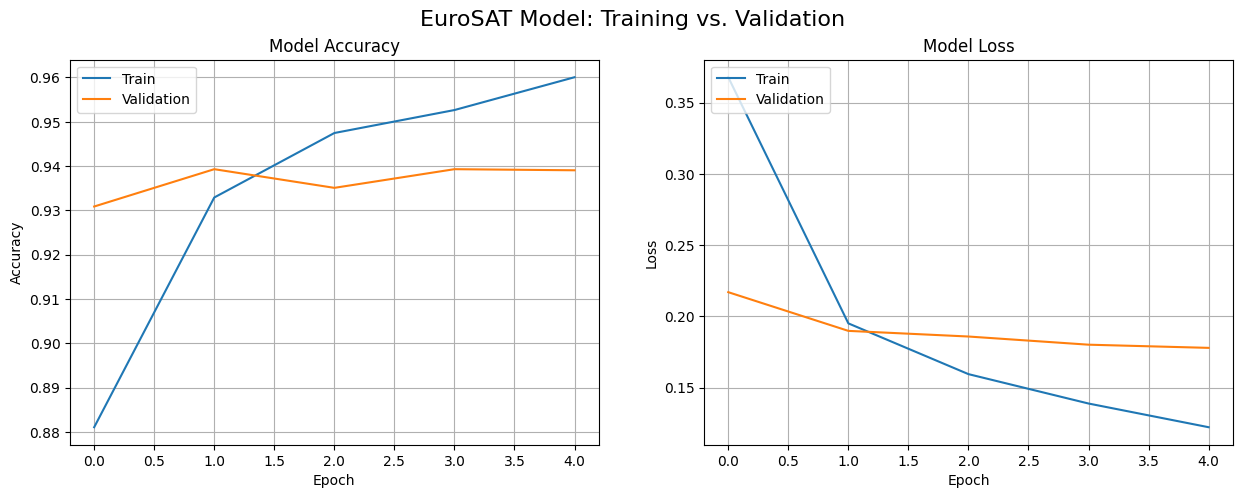

Validation Accuracy: 0.9378
Test Accuracy:       0.9375


In [53]:
# Report validation and test accuracy here
plot_history(sat_history, "EuroSAT Model: Training vs. Validation")

sat_val_loss, sat_val_acc = model_sat.evaluate(val_ds_sat, verbose=0)
sat_test_loss, sat_test_acc = model_sat.evaluate(test_ds_sat, verbose=0)
print(f"Validation Accuracy: {sat_val_acc:.4f}")
print(f"Test Accuracy:       {sat_test_acc:.4f}")


## 2D — Confusion Matrix and Discussion

Build a confusion matrix for your model's test set predictions.

**Answer:** Which land-use classes get confused most often? Does that make visual sense to you?

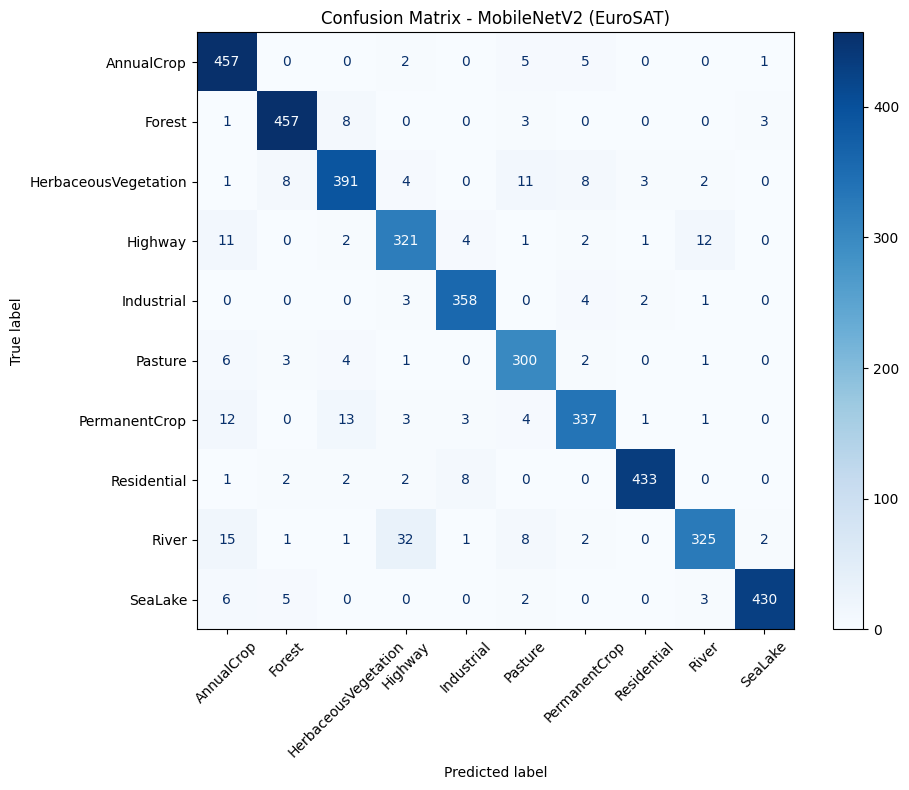

River -> Highway: 32
River -> AnnualCrop: 15
PermanentCrop -> HerbaceousVegetation: 13
PermanentCrop -> AnnualCrop: 12
Highway -> River: 12


In [54]:
# Build your confusion matrix here
def predict_with_labels(model, ds):
    # Gather labels and predictions in the same pass so they stay aligned (datasets are shuffled)
    y_true, y_prob = [], []
    for images, labels in ds:
        y_true.append(labels.numpy())
        y_prob.append(model.predict(images, verbose=0))
    return np.concatenate(y_true), np.concatenate(y_prob)

y_true_sat, sat_probs = predict_with_labels(model_sat, test_ds_sat)
y_pred_sat = np.argmax(sat_probs, axis=1)

cm_sat = confusion_matrix(y_true_sat, y_pred_sat)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_sat, display_labels=class_names_sat).plot(
    cmap="Blues", ax=ax, values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix - MobileNetV2 (EuroSAT)")
plt.tight_layout()
plt.show()

# Top confused (true -> predicted) pairs
pairs = [(cm_sat[i, j], class_names_sat[i], class_names_sat[j])
         for i in range(10) for j in range(10) if i != j]
for n, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"{t} -> {p}: {n}")

*Your answer:*
River was most often confused as Highway (33 times), followed by PermanentCrop as HerbaceousVegetation (15 times) and River as AnnualCrop (14 times). This makes visual sense. From above, a river and a highway are both long, thin, winding strips cutting through the surrounding land, and permanent crops (orchards and vineyards) and herbaceous vegetation are both textured green vegetation that probably look pretty alike at this resolution.



---
# Part 3: Compare the Two Domains

Fill in your own results:

| | Fire/Smoke | EuroSAT |
|---|---|---|
| Validation Accuracy |0.9784 | 0.9400|
| Test Accuracy | 0.9378 | 0.9375|

**Answer:**
1. MobileNetV2 was originally trained on ImageNet, ordinary ground-level photos of everyday objects. Which of your two datasets do you think is the closer match to that original training, and which is the bigger mismatch? Use your actual results as evidence.
2. For each dataset, do you think there's room for improvement if you could adjust part of the pretrained model itself, rather than just the new layer on top? Would you expect that to matter more for one dataset than the other? Why?

*Your answers:*




---
# Part 4: Reflection

Answer in 4 to 6 sentences:

1. Did anything about the Fire dataset's composition affect how you approached splitting or evaluating it? Explain.
2. What's the actual difference between the output layer, activation, and loss function you used in Part 1 versus Part 2? Why does that difference exist?
3. Based on your results, does a pretrained model's usefulness depend only on how good the model is, or also on how well its original training matches your task? Explain using your own two results as evidence.

*Your answers:*

1. I think the fire dataset is the closer match to ImageNet because it's normal ground-level photos, and EuroSAT is the bigger mismatch because satellite images look really different from everyday objects. The validation results back this up (fire 98.56% vs EuroSAT 93.90%), but the test accuracies ended up almost the same (93.78% vs 93.75%). The fire test set is really small (around 160 images), so that number can jump around a lot and I wouldn't read too much into it.

2. Yes, I think both could get better if we unfroze some of the MobileNetV2 layers and fine-tuned them with a small learning rate. It would help EuroSAT the most, because satellite images are so different from ImageNet that the frozen features aren't a perfect fit. Fire images already look like ImageNet photos, so there's less room to improve there.

---
## Done!

Save this notebook back to your GitHub fork, then submit your two links on Canvas.

1. Yes, the fire dataset has way more fire images (755) than non-fire (244), so a model could get a high accuracy by just guessing fire most of the time. Because of that I used a confusion matrix instead of only looking at accuracy.

2. In Part 1 I used 1 output unit with sigmoid and binary cross-entropy because it's just fire or not fire. In Part 2 I used 10 output units with softmax and sparse categorical cross-entropy because there are 10 land-use classes and only one is right.

3. It depends on both. MobileNetV2 is a good model, but EuroSAT scored lower on validation (93.90% vs 98.56% for fire) because satellite images are so different from the ImageNet photos it learned from.